In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
import numpy as np
from torch.utils.data import DataLoader
from datasets import load_dataset
from torch.amp import autocast, GradScaler
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.version.cuda)
print(f"running on {device}")

13.0
running on cuda


In [ ]:
class EncoderLayer(nn.Module):
    def __init__(self, in_channels, out_channels, p_dropout=0.1):
        super().__init__()
        self.c1 = nn.Conv2d(in_channels, out_channels, 3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.act1 = nn.GELU()
        
        self.c2 = nn.Conv2d(out_channels, out_channels, 3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.act2 = nn.GELU()
        
        self.c3 = nn.Conv2d(out_channels, out_channels, 3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm2d(out_channels)
        self.act3 = nn.GELU()
        
        self.downsample = nn.MaxPool2d(2, stride=2)
        self.dropout = nn.Dropout2d(p_dropout)

    def forward(self, x):
        h = self.act1(self.bn1(self.c1(x)))
        h = self.act2(self.bn2(self.c2(h)))
        h = self.act3(self.bn3(self.c3(h)))
        h = self.dropout(h)
        return self.downsample(h), h

class DecoderLayer(nn.Module):
    def __init__(self, in_channels, skip_in_channels, out_channels, p_dropout=0.1):
        super().__init__()
        self.c1 = nn.Conv2d(skip_in_channels + in_channels, in_channels, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.act1 = nn.GELU()
        
        self.c2 = nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(in_channels)
        self.act2 = nn.GELU()
        
        self.c3 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm2d(out_channels)
        self.act3 = nn.GELU()
        
        self.upconv = nn.ConvTranspose2d(in_channels, in_channels, 2, 2)
        self.dropout = nn.Dropout2d(p_dropout)

    def forward(self, x_skip, x_lowres):
        upscaled = self.upconv(x_lowres)
        x = torch.cat([upscaled, x_skip], 1)
        
        h = self.act1(self.bn1(self.c1(x)))
        h = self.act2(self.bn2(self.c2(h)))
        h = self.act3(self.bn3(self.c3(h)))
        
        return self.dropout(h)

class UNet(nn.Module):
    def __init__(self, output_classes=20, layer_count=2, channel_counts=None):
        super().__init__()
        self.layer_count = layer_count
        
        if channel_counts is None or len(channel_counts) == 0:
            t = [2**(i+6) for i in range(layer_count)]
            channel_counts = [3] + t + t[-2::-1] + [output_classes]

        assert len(channel_counts) == 2 * layer_count + 1
        assert channel_counts[0] == 3
        assert channel_counts[-1] == output_classes

        self.encoders = nn.ModuleList([
            EncoderLayer(channel_counts[i], channel_counts[i+1]) for i in range(layer_count)
        ])

        # Added BatchNorm to the bottom layer as well
        self.bottom_layer = nn.Sequential(
            nn.Conv2d(channel_counts[layer_count], channel_counts[layer_count], kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(channel_counts[layer_count]),
            nn.GELU(),
            nn.Conv2d(channel_counts[layer_count], channel_counts[layer_count], kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(channel_counts[layer_count]),
            nn.GELU()
        )

        self.decoders = nn.ModuleList([
            DecoderLayer(channel_counts[i], channel_counts[i], channel_counts[i+1]) 
            for i in range(layer_count, 2 * layer_count)
        ])

    def forward(self, x):
        activations = []
        for encoder in self.encoders:
            x, a_map = encoder(x)
            activations.append(a_map)

        up = self.bottom_layer(x)

        for i, decoder in enumerate(self.decoders):
            up = decoder(activations[self.layer_count - i - 1], up)

        return up

In [3]:
train_ds = load_dataset(
    "tanganke/cityscapes",
    split="train",
    # streaming=True
)

val_ds = load_dataset(
    "tanganke/cityscapes",
    split="validation",
    # streaming=True
)

def prepare_example(example):
    image = torch.tensor(
        np.array(example["image"]),
        dtype=torch.float32
    ) 

    mask = torch.tensor(
        np.array(example["segmentation_19"]),
        dtype=torch.long
    )

    mask[mask == -1] = 19
    

    return {
        "image": image,
        "mask": mask,
    }

train_ds = train_ds.with_transform(prepare_example)
val_ds = val_ds.with_transform(prepare_example)

train_loader = DataLoader(
    train_ds,
    batch_size=16,
    num_workers=4,       # Increased from 2
    pin_memory=True,     # Added for faster GPU transfer
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=16,
    num_workers=4,
    pin_memory=True,
    shuffle=False
)

In [ ]:
scaler = GradScaler('cuda')

# Re-initialize model, criterion, and optimizer after changing the architecture
model = UNet(output_classes=20, layer_count=6).to(device)
criterion = torch.nn.CrossEntropyLoss(ignore_index=-1)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

In [ ]:
for epoch in range(50):
    model.train()
    running_loss = 0.0
    batches = 0

    for batch in tqdm(train_loader):
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)

        optimizer.zero_grad()

        # 1. Forward pass in mixed precision (FP16)
        with autocast('cuda'):
            logits = model(images)
            
        # 2. Compute loss in FP32 (Crucial: prevents log_softmax overflow)
        loss = criterion(logits.float(), masks)

        # 3. Backward pass and optimization
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        
        # Gradient clipping is good, keep it
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        batches += 1

    print(f"Epoch {epoch + 1}: loss = {running_loss / batches:.4f}")

100%|██████████| 186/186 [01:45<00:00,  1.76it/s]


Epoch 1: loss = 1.8940


100%|██████████| 186/186 [01:36<00:00,  1.93it/s]


Epoch 2: loss = 1.6139


100%|██████████| 186/186 [01:37<00:00,  1.91it/s]


Epoch 3: loss = 1.4900


... (90 outputs left out)

100%|██████████| 186/186 [01:31<00:00,  2.03it/s]


Epoch 49: loss = 0.5700


100%|██████████| 186/186 [01:32<00:00,  2.01it/s]

Epoch 50: loss = 0.5668


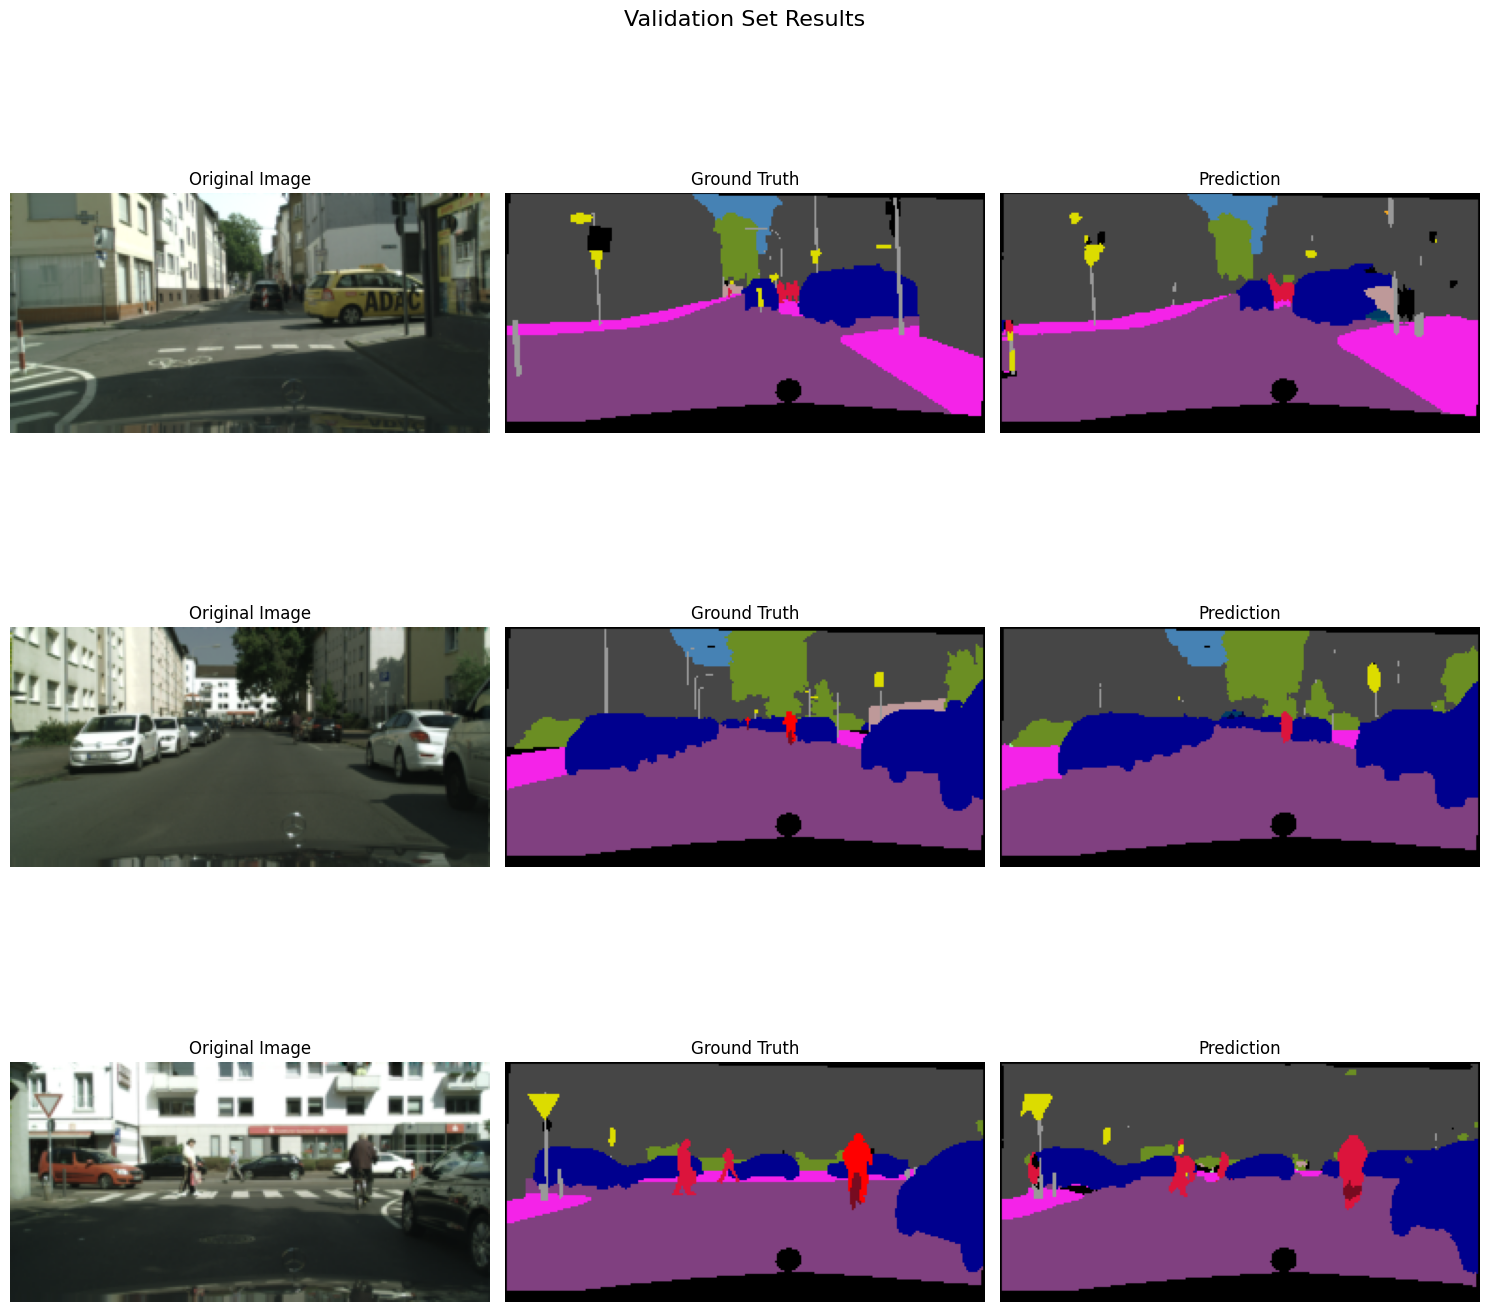

UNet(
  (encoders): ModuleList(
    (0): EncoderLayer(
      (c1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act1): GELU(approximate='none')
      (c2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act2): GELU(approximate='none')
      (c3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act3): GELU(approximate='none')
      (downsample): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (dropout): Dropout2d(p=0.1, inplace=False)
    )
    (1): EncoderLayer(
      (c1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=Tr

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 1. Define the official Cityscapes 19-class color palette (RGB)
CITYSCAPES_COLORS = np.array([
    [128, 64, 128],  # 0: road
    [244, 35, 232],  # 1: sidewalk
    [70, 70, 70],    # 2: building
    [102, 102, 156], # 3: wall
    [190, 153, 153], # 4: fence
    [153, 153, 153], # 5: pole
    [250, 170, 30],  # 6: traffic light
    [220, 220, 0],   # 7: traffic sign
    [107, 142, 35],  # 8: vegetation
    [152, 251, 152], # 9: terrain
    [70, 130, 180],  # 10: sky
    [220, 20, 60],   # 11: person
    [255, 0, 0],     # 12: rider
    [0, 0, 142],     # 13: car
    [0, 0, 70],      # 14: truck
    [0, 60, 100],    # 15: bus
    [0, 80, 100],    # 16: train
    [0, 0, 230],     # 17: motorcycle
    [119, 11, 32],    # 18: bicycle,
    [0,0,0]
], dtype=np.uint8)

def colorize_mask(mask_tensor):
    """Converts a 2D tensor of class indices into an RGB image."""
    mask_np = mask_tensor.cpu().numpy()
    h, w = mask_np.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8) # Defaults to black for ignore_index (-1)
    
    for i in range(19):
        color_mask[mask_np == i] = CITYSCAPES_COLORS[i]
        
    return color_mask

# 2. Set model to evaluation mode and disable gradient calculation
model.eval()
with torch.no_grad():
    # Grab a single batch from the validation loader
    batch = next(iter(val_loader))
    images = batch["image"].to(device)
    masks = batch["mask"]
    
    # Get predictions
    logits = model(images)
    # Argmax over the class dimension (dim=1) to get the predicted class indices
    preds = torch.argmax(logits, dim=1) 

# 3. Plot the results (Showing 3 examples from the batch)
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle("Validation Set Results", fontsize=16)

for i in range(3):
    # --- Original Image ---
    img = images[i].cpu().numpy()
    # Ensure image is in (H, W, C) format for matplotlib
    if img.shape[0] == 3: 
        img = np.transpose(img, (1, 2, 0))
    # Normalize to 0-1 for display (since you didn't normalize in prepare_example)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8) 
    
    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Original Image")
    axes[i, 0].axis('off')
    
    # --- Ground Truth Mask ---
    gt_color = colorize_mask(masks[i])
    axes[i, 1].imshow(gt_color)
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis('off')
    
    # --- Predicted Mask ---
    pred_color = colorize_mask(preds[i])
    axes[i, 2].imshow(pred_color)
    axes[i, 2].set_title("Prediction")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

# Don't forget to set back to train mode if you are continuing training in the next cell!
model.train()